# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [3]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [4]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [5]:
df = pd.read_csv(PLIK_LODZ, sep=";")

print("Pierwsze wiersze:")
print(df.head())

print("\nWymiary:")
print(df.shape)

print("\nInformacje o kolumnach:")
df.info()

Pierwsze wiersze:
                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie

Wymiary:
(65, 4)

Informacje o kolumnach:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   name     65 non-null     object
 1   rok      65 non-null     int64 
 2   wartość  65 non-null     int64 
 3   zmienna  65 non-null     object
dtypes: int64(2), object(2)
memory usage: 2.2+ KB


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separatorem jest średnik. Kolumna wartość ma typ liczbowy (int64). Nazwy kolumn z polskimi znakami wczytały się poprawnie.

## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [11]:
# 1)

print(df["zmienna"].value_counts())

# 2)
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka

zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [7]:
roznica = (szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"]
print("Różnica:")
print(roznica)

Różnica:
rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [14]:
# 1)

print(szeroka.describe())

# 2)

zmiana_procentowa = ((szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012]) * 100
print("\nZmiana procentowa:")
print(zmiana_procentowa)

# 3)

szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]
szeroka


zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00

Zmiana procentowa:
zmienna
absolwenci ogółem   -41.29
kobiety             -30.22
mężczyźni           -29.14
ogółem              -29.79
uczelnie            -31.82
dtype: float64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie,udzial_kobiet,studenci_na_uczelnie
rok,,,,,,,
2012,24825,55265,36281,91546,22,0.60,4161.18
2013,22590,50007,33464,83471,22,0.60,3794.14
2014,21343,48220,32456,80676,23,0.60,3507.65
2015,19835,45584,30769,76353,21,0.60,3635.86
2016,17662,44053,29908,73961,20,0.60,3698.05
2017,19281,42990,29029,72019,22,0.60,3273.59
2018,17046,39312,26253,65565,20,0.60,3278.25
2019,15819,38146,26297,64443,19,0.59,3391.74
2020,14082,39170,26155,65325,18,0.60,3629.17


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

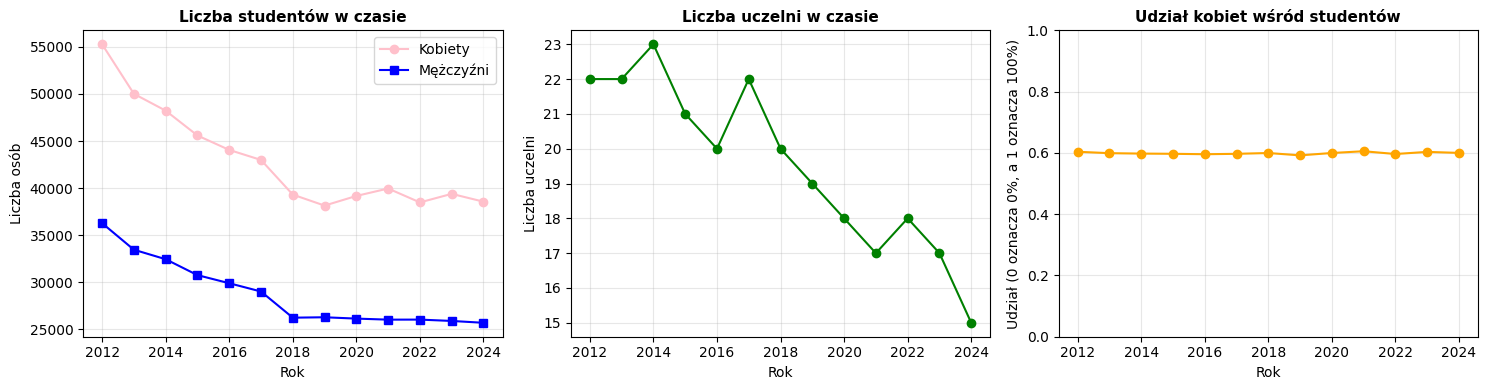

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1)

axes[0].plot(szeroka.index, szeroka["kobiety"], marker="o", color="pink", label="Kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="s", color="blue", label="Mężczyźni")
axes[0].set_title("Liczba studentów w czasie", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2)

axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", color="green")
axes[1].set_title("Liczba uczelni w czasie", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")
axes[1].grid(True, alpha=0.3)


# 3)

axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", color="orange")
axes[2].set_title("Udział kobiet wśród studentów", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział (0 oznacza 0%, a 1 oznacza 100%)")
axes[2].set_ylim(0, 1)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* Nastąpił spadek studentów. Poza tym - zmniejszyła się liczba uczelni. Natomiast udział kobiet wśród studentów utrzymuje się stale, na poziomie ~60%.

## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Saldo migracji w Łodzi · **link:** https://otwarte.miasto.lodz.pl/wp-content/uploads/2026/01/saldo-migracji-w-odzi.csv · **data pobrania:** 22.10.2026

In [22]:
# 2)

PLIK_MIGRACJA = "saldo-migracji-w-odzi.csv"
df_migracja = pd.read_csv(PLIK_MIGRACJA, sep=";")

# 3)

print(df_migracja.head())
df_migracja.info()

# 4)

print("\nLiczba braków danych:")
print(df_migracja.isna().sum())

      name   rok  wartość         zmienne
0  Ludność  1995      146  saldo migracji
1  Ludność  1996     -145  saldo migracji
2  Ludność  1997      -14  saldo migracji
3  Ludność  1998      183  saldo migracji
4  Ludność  1999     -409  saldo migracji
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   name     31 non-null     object
 1   rok      31 non-null     int64 
 2   wartość  31 non-null     int64 
 3   zmienne  31 non-null     object
dtypes: int64(2), object(2)
memory usage: 1.1+ KB

Liczba braków danych:
name       0
rok        0
wartość    0
zmienne    0
dtype: int64


In [34]:
# 3)

szeroka_migracja = df_migracja.pivot(index="rok", columns="zmienne", values="wartość")
szeroka_migracja

# 5)

print(szeroka_migracja.describe())

zmienne  saldo migracji
count             31.00
mean           -1045.87
std              596.55
min            -2072.00
25%            -1449.00
50%            -1198.00
75%             -750.50
max              183.00


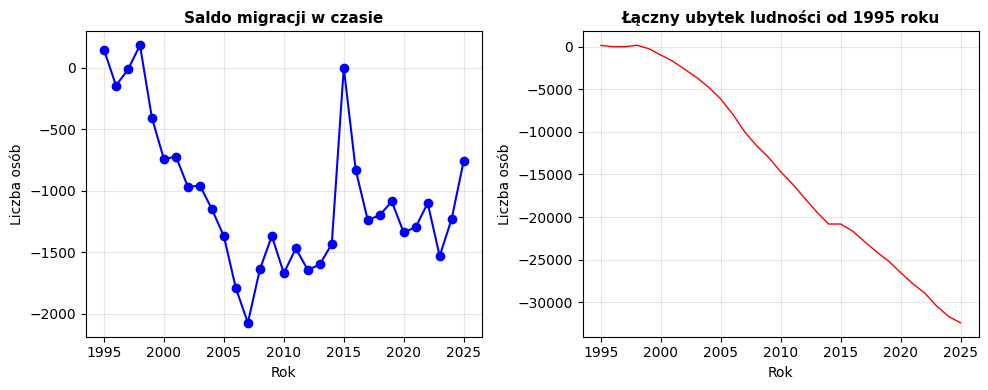

In [41]:
# 6)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(szeroka_migracja.index, szeroka_migracja["saldo migracji"], marker="o", color="blue")
axes[0].set_title("Saldo migracji w czasie", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba osób")
axes[0].grid(True, alpha=0.3)

szeroka_migracja["skumulowane_saldo"] = szeroka_migracja["saldo migracji"].cumsum()

axes[1].plot(szeroka_migracja.index, szeroka_migracja["skumulowane_saldo"], color="red", linewidth=1)
axes[1].set_title("Łączny ubytek ludności od 1995 roku", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba osób")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Wnioski:** Wykres pokazuje, że saldo migracji przez niemal cały czas było ujemne. Dodatnie wartości pojawiły się tylko w 1995 i 1998 roku. Skumulowany wykres pokazuje, że w latach 1995-2025 Łódź straciła, z powodu migracji, ponad 30 tysięcy mieszkańców.

---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [42]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

          age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


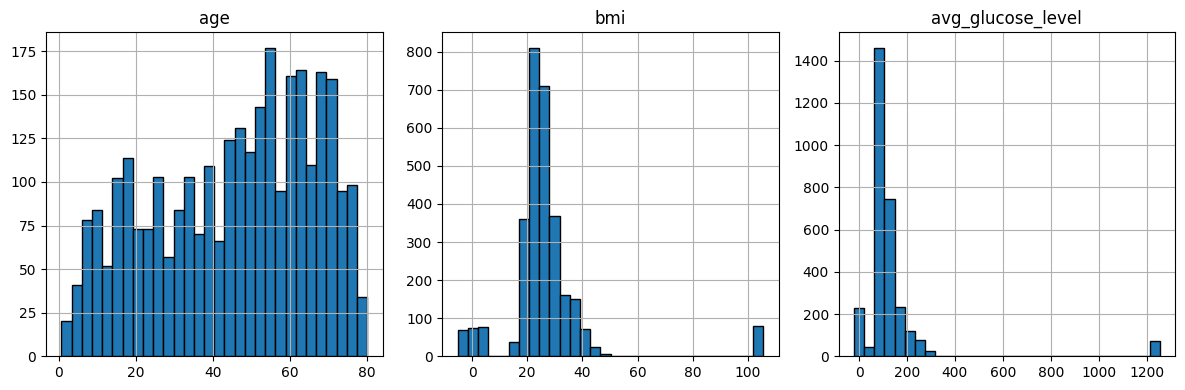

In [43]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]
print(pacjenci[LICZBOWE].describe())

pacjenci[LICZBOWE].hist(figsize=(12, 4), layout=(1, 3), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* age - od 0.67 do 80.00 (możliwe), bmi - od -5.20 do 105.60 (bmi nie może być ujemne i wartości powyżej 100 są skrajnie rzadkie, podejrzane), avg_glucose_level (średni poziom glukozy) - od -21.40 do 1254.60 (nie może być ujemny poziom we krwi, a 1254 to już poziom śmiertelny).

## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [44]:
# 1)

zle_bmi = ~pacjenci["bmi"].between(10, 60)
zla_glukoza = ~pacjenci["avg_glucose_level"].between(20, 800)
zly_wiek = ~pacjenci["age"].between(0, 120)

# 2)

dowolna_zla = zle_bmi | zla_glukoza | zly_wiek

print(f"Niemożliwe bmi: {zle_bmi.sum()}")
print(f"Niemożliwa glukoza: {zla_glukoza.sum()}")
print(f"Niemożliwy wiek: {zly_wiek.sum()}")
print(f"Co najmniej jedna niemożliwa wartość: {dowolna_zla.sum()}")


# 3)

pacjenci.loc[zle_bmi, "bmi"] = np.nan
pacjenci.loc[zla_glukoza, "avg_glucose_level"] = np.nan
pacjenci.loc[zly_wiek, "age"] = np.nan

Niemożliwe bmi: 300
Niemożliwa glukoza: 300
Niemożliwy wiek: 0
Co najmniej jedna niemożliwa wartość: 560


          age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91


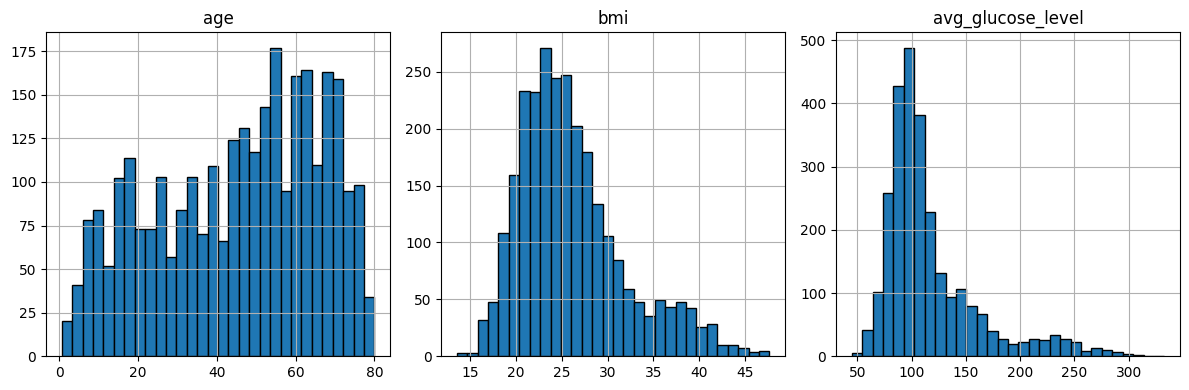

In [45]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?

print(pacjenci[LICZBOWE].describe())

pacjenci[LICZBOWE].hist(figsize=(12, 4), layout=(1, 3), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

**Odpowiedź:** Zniknęły skrajne, nienaturalne słupki. Rozkłady stały się możliwe.

## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

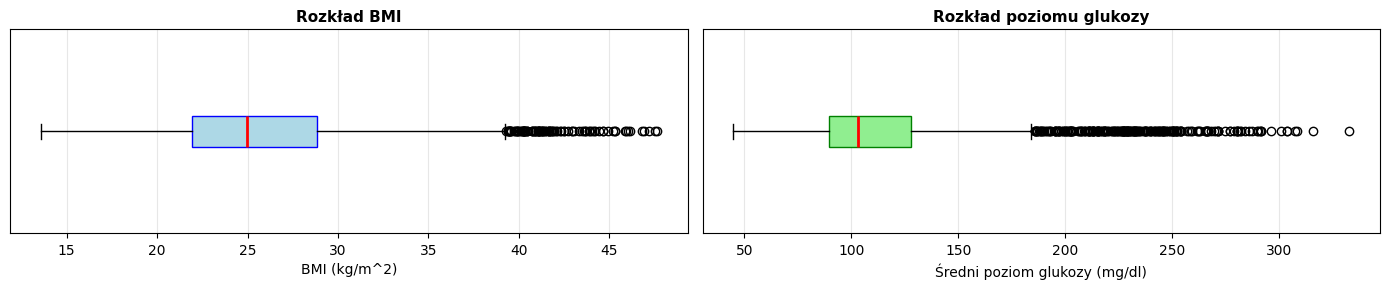

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

# bmi
axes[0].boxplot(pacjenci["bmi"].dropna(), orientation="horizontal", patch_artist=True, boxprops=dict(facecolor="lightblue", color="blue"), medianprops=dict(color="red", linewidth=2))
axes[0].set_title("Rozkład BMI", fontsize=11, fontweight="bold")
axes[0].set_xlabel("BMI (kg/m^2)")
axes[0].set_yticks([])
axes[0].grid(axis="x", alpha=0.3)

# glukoza
axes[1].boxplot(pacjenci["avg_glucose_level"].dropna(), orientation="horizontal", patch_artist=True, boxprops=dict(facecolor="lightgreen", color="green"), medianprops=dict(color="red", linewidth=2))
axes[1].set_title("Rozkład poziomu glukozy", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Średni poziom glukozy (mg/dl)")
axes[1].set_yticks([])
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

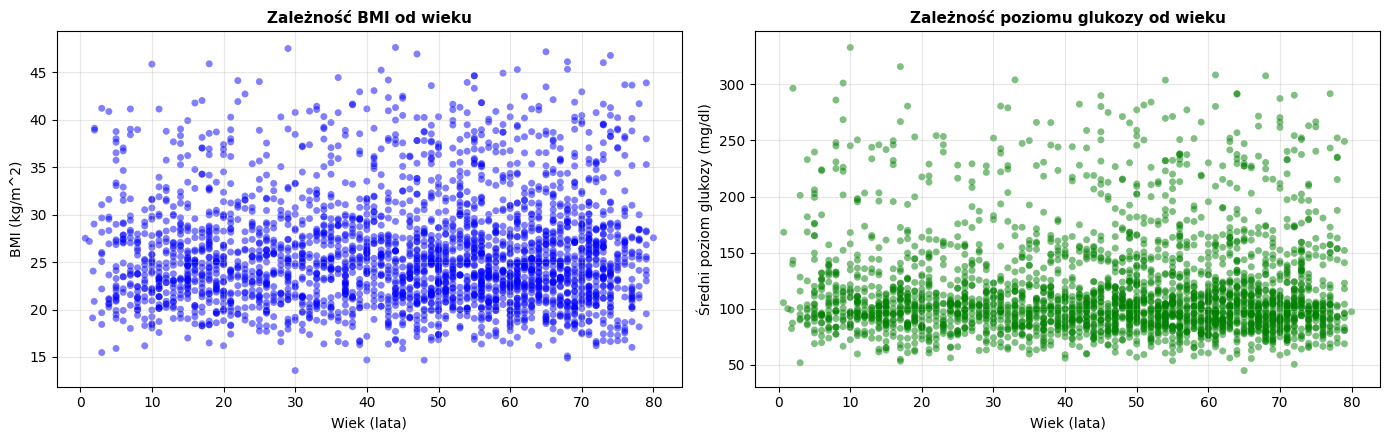

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(pacjenci["age"], pacjenci["bmi"], alpha=0.5, color="blue", edgecolor="none", s=25)
axes[0].set_title("Zależność BMI od wieku", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Wiek (lata)")
axes[0].set_ylabel("BMI (kg/m^2)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(pacjenci["age"], pacjenci["avg_glucose_level"], alpha=0.5, color="green", edgecolor="none", s=25)
axes[1].set_title("Zależność poziomu glukozy od wieku", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Wiek (lata)")
axes[1].set_ylabel("Średni poziom glukozy (mg/dl)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. Więcej punktów poza wąsami jest dla rozkładu poziomu glukozy. Występują tylko po prawej stronie.
2. Pojawiają się u osób w różnym wieku, ale najwięcej jest ich u osób starszych. Wynik 300mg/dl dla 10-latka to rzadki przypadek, ale możliwy.

## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [52]:
def maska_iqr(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    dolny = q1 - k * iqr
    gorny = q3 + k * iqr
    return ((s < dolny) | (s > gorny)) & s.notna()

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return (z.abs() > prog) & s.notna()

def maska_mad(s, prog=3.5):
    mediana = s.median()
    mad = (s - mediana).abs().median()
    z_mad = (0.6745 * (s - mediana).abs()) / mad
    return (z_mad > prog) & s.notna()

Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [53]:
zmienne = ["age", "bmi", "avg_glucose_level"]

dane_por = []
for kol in zmienne:
    s = pacjenci[kol]
    dane_por.append({
        "zmienna": kol,
        "IQR 1.5": maska_iqr(s, k=1.5).sum(),
        "IQR 3": maska_iqr(s, k=3.0).sum(),
        "z-score": maska_z(s, prog=3).sum(),
        "MAD": maska_mad(s, prog=3.5).sum(),
        "skew": s.skew()
    })

porownanie = pd.DataFrame(dane_por).set_index("zmienna")
porownanie

,IQR 1.5,IQR 3,z-score,MAD,skew
zmienna,,,,,
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Dla wieku nic nie wykrywa bo wiek jest prawidłowy (w granicach biologicznego życia), bez długich ogonów. Natomiast dla glukozy wyniki się różnią, ponieważ ta wartość ma skłonność do skośności prawostronnej (1.80), czyli ma długi prawy ogon - z-score w tym przypadku wykrywa najmniej bo wysokie wartości podbijają średnią, a IQR i MAD opierają się na kwartylach i medianie, więc traktują cały prawy ogon za odstające wartości.

### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

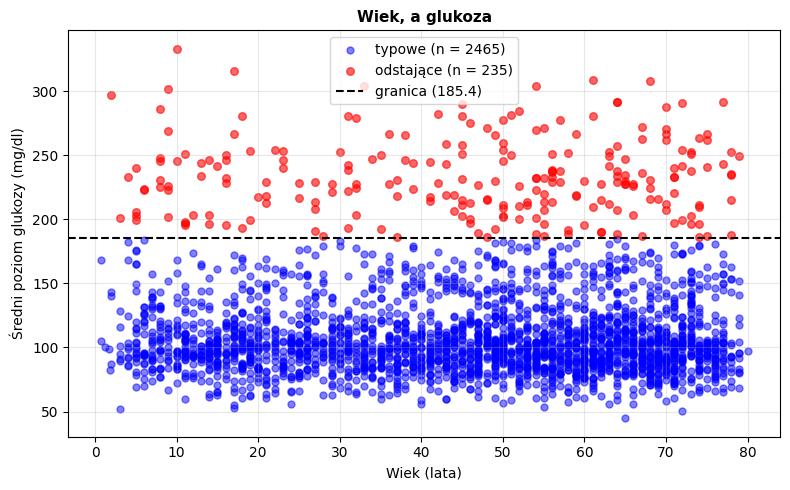

Liczba punktów odstających: 235


In [58]:
s_glukoza = pacjenci["avg_glucose_level"]
q1 = s_glukoza.quantile(0.25)
q3 = s_glukoza.quantile(0.75)
iqr = q3 - q1
gorna_granica = q3 + 1.5 * iqr
odstajace_glukoza = maska_iqr(s_glukoza, k=1.5)
typowe_glukoza = (~odstajace_glukoza) & s_glukoza.notna()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(pacjenci.loc[typowe_glukoza, "age"], pacjenci.loc[typowe_glukoza, "avg_glucose_level"], color="blue", alpha=0.5, s=25, label=f"typowe (n = {typowe_glukoza.sum()})")
ax.scatter(pacjenci.loc[odstajace_glukoza, "age"], pacjenci.loc[odstajace_glukoza, "avg_glucose_level"], color="red", alpha=0.6, s=30, label=f"odstające (n = {odstajace_glukoza.sum()})")
ax.axhline(gorna_granica, color="black", linestyle="--", linewidth=1.5, label=f"granica ({gorna_granica:.1f})")
ax.set_title("Wiek, a glukoza", fontsize=11, fontweight="bold")
ax.set_xlabel("Wiek (lata)")
ax.set_ylabel("Średni poziom glukozy (mg/dl)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Liczba punktów odstających: {odstajace_glukoza.sum()}")

**Odpowiedź:** Zgadza się.

### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

% udarów u pacjentów z glukozą odstającą: 21.70%
% udarów u pozostałych pacjentów: 21.10%


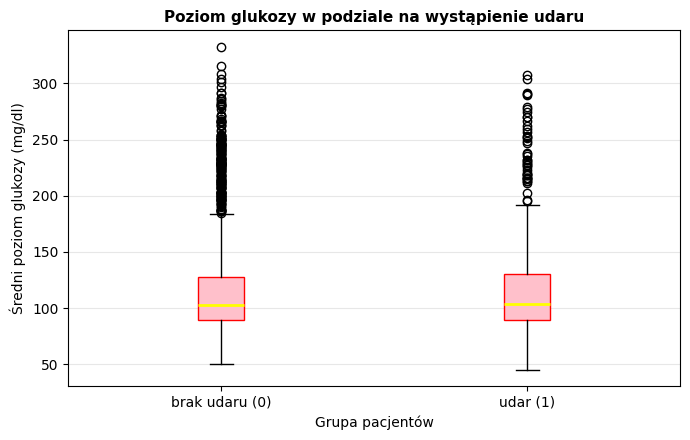

In [62]:
odsetek_odstajace = pacjenci.loc[odstajace_glukoza, "stroke"].mean() * 100
odsetek_typowe = pacjenci.loc[typowe_glukoza, "stroke"].mean() * 100

print(f"% udarów u pacjentów z glukozą odstającą: {odsetek_odstajace:.2f}%")
print(f"% udarów u pozostałych pacjentów: {odsetek_typowe:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4.5))

dane_brak_udaru = pacjenci.loc[(pacjenci["stroke"] == 0), "avg_glucose_level"].dropna()
dane_udar = pacjenci.loc[(pacjenci["stroke"] == 1), "avg_glucose_level"].dropna()

ax.boxplot([dane_brak_udaru, dane_udar], tick_labels=["brak udaru (0)", "udar (1)"], patch_artist=True, boxprops=dict(facecolor="pink", color="red"), medianprops=dict(color="yellow", linewidth=2))
ax.set_title("Poziom glukozy w podziale na wystąpienie udaru", fontsize=11, fontweight="bold")
ax.set_xlabel("Grupa pacjentów")
ax.set_ylabel("Średni poziom glukozy (mg/dl)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie należy, ponieważ te wartości to nie błąd pomiaru tylko zjawisko, które faktycznie może wystąpić. W tym zbiorze odsetek udarów jest niemal identyczny, ale możliwy. Ponadto, w grupie osób z udarem, rozkład osób z udarem ma nieznacznie wyżej położone pudełko, ale dużo wartości podwyższonych.  

## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [65]:
# 1)

tabela_krzyzowa = pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"])
print(tabela_krzyzowa)

# 2)

dziecko_pali = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
maluch_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

# 3)

print(f"\nLiczba dzieci, które palą/paliły: {dziecko_pali.sum()}")
print(f"Liczba małych dzieci (<= 3 lata) oznaczonych jako student: {maluch_student.sum()}")
print("\nZnalezieni pacjenci (dziecko_pali):")
display(pacjenci[dziecko_pali])
print("\nZnalezieni pacjenci (maluch_student):")
display(pacjenci[maluch_student])

smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75

Liczba dzieci, które palą/paliły: 15
Liczba małych dzieci (<= 3 lata) oznaczonych jako student: 1

Znalezieni pacjenci (dziecko_pali):


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
111,A678646,Female,9.00,0,0,False,children,Rural,96.59,22.24,smokes,0
290,A844121,Male,13.00,0,0,False,children,Urban,163.31,20.14,smokes,0
336,A135365,Female,12.00,0,0,False,children,Urban,135.59,27.15,smokes,0
352,A810636,Male,14.00,0,0,False,children,Rural,203.26,NaN,smokes,0
361,A843508,Male,2.00,0,0,False,children,Urban,143.14,39.11,smokes,0
578,A161666,Male,3.00,0,0,False,children,Urban,NaN,15.47,smokes,0
600,A623587,Male,10.00,0,0,False,children,Urban,NaN,20.93,smokes,0
613,A892803,Male,13.00,0,0,False,children,Urban,132.17,25.04,smokes,0
741,A560170,Male,13.00,0,0,False,children,Urban,243.95,25.59,smokes,0
767,A390530,Male,13.00,0,0,False,children,Urban,91.28,28.47,smokes,0



Znalezieni pacjenci (maluch_student):


,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
52,A582477,Female,1.80,0,0,False,student,Rural,82.20,24.05,formerly smoked,0


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie, ponieważ IQR/z-score działa jednowymiarowo, a tu mamy tabelę tekstową. Poza tym - wiek <= 3 jest poprawny, ale nielogiczne jest przypisanie go do roli "student".

## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [68]:
from scipy.stats import chi2

# 1)

X = pacjenci[LICZBOWE].dropna()

# 2)

Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)

# 3)

prog = chi2.ppf(0.99, df=3)
odstajacy = d2 > prog
print(f"Wyznaczony próg: {prog:.2f}")
print(f"Liczba pacjentów przekraczających próg: {odstajacy.sum()}")

# 4)

kwadraty_z = Z.loc[odstajacy] ** 2
glowna_cecha = kwadraty_z.idxmax(axis=1)
print("Cecha:")
print(glowna_cecha.value_counts())

Wyznaczony próg: 11.34
Liczba pacjentów przekraczających próg: 73
Cecha:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Liczba pacjentów odstających PRZED: 73
Liczba pacjentów odstających PO: 31


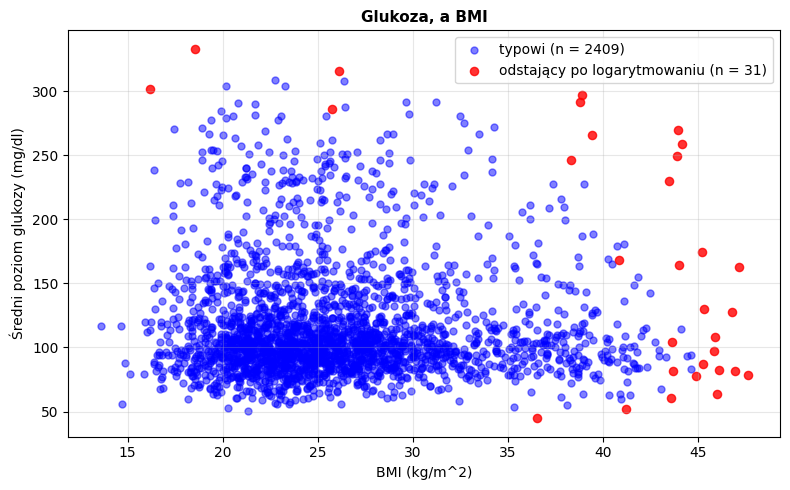


X.corr():
                   age   bmi  avg_glucose_level
age               1.00  0.02               0.01
bmi               0.02  1.00              -0.02
avg_glucose_level 0.01 -0.02               1.00


In [71]:
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])
Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)

odstajacy_log = d2_log > prog
print(f"Liczba pacjentów odstających PRZED: {odstajacy.sum()}")
print(f"Liczba pacjentów odstających PO: {odstajacy_log.sum()}")

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(X.loc[~odstajacy_log, "bmi"], X.loc[~odstajacy_log, "avg_glucose_level"], color="blue", alpha=0.5, s=25, label=f"typowi (n = {(~odstajacy_log).sum()})")
ax.scatter(X.loc[odstajacy_log, "bmi"], X.loc[odstajacy_log, "avg_glucose_level"], color="red", alpha=0.8, s=35, label=f"odstający po logarytmowaniu (n = {odstajacy_log.sum()})")
ax.set_title("Glukoza, a BMI", fontsize=11, fontweight="bold")
ax.set_xlabel("BMI (kg/m^2)")
ax.set_ylabel("Średni poziom glukozy (mg/dl)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("\nX.corr():")
print(X.corr())

✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, ponieważ korelacje między cechami są prawie równe.

### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [73]:
from sklearn.ensemble import IsolationForest

clf = IsolationForest(contamination=0.01, random_state=0)
pred = clf.fit_predict(X_log)
odstajace_if = (pred == -1)
wspolne = odstajace_if & odstajacy_log

print(f"Liczba wykrytych przez isolation forest: {odstajace_if.sum()}")
print(f"Liczba wykrytych przez d2_log: {odstajacy_log.sum()}")
print(f"Liczba pacjentów wskazanych jednocześnie: {wspolne.sum()}")

Liczba wykrytych przez isolation forest: 25
Liczba wykrytych przez d2_log: 31
Liczba pacjentów wskazanych jednocześnie: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [75]:
flagi = pd.DataFrame(index=oryginal.index)

flagi["niemozliwa_wartosc"] = ((~oryginal["bmi"].between(10, 60)) | (~oryginal["avg_glucose_level"].between(20, 800)) | (~oryginal["age"].between(0, 120)))
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"], k=1.5)
flagi["nielogiczna_kategoria"] = dziecko_pali | maluch_student
flagi["odlegly_od_srodka"] = (d2_log > prog).reindex(oryginal.index, fill_value=False)
print("Liczba pacjentów z poszczególnymi flagami:")
print(flagi.sum())
print("Liczba pacjentów z co najmniej jedną flagą:")
print(flagi.any(axis=1).sum())

Liczba pacjentów z poszczególnymi flagami:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
Liczba pacjentów z co najmniej jedną flagą:
806


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN/usunąć | są to błędy pomiaru |
| wysoka glukoza (IQR) | zostawić/ | to realny stan z ważną informacją |
| nielogiczne kategorie | poprawić/NaN | niektóre błędy można łatwo poprawić, np. na podstawie wieku |
| odlegli od środka | flaga | nie trzeba tracić rzadkich pacjentów, wystarczy oznaczyć ich dodatkową flagą |